# **MODULE 12 — DIGITAL AUDIO FILTERING 🎧**

**Core DSP Concept**

**Important for Speech Processing**

In Module 11, we learned about audio noise, SNR, noise suppression and signal quality.

Now let's learn how to modify an audio signal using **digital filters**.

Imagine recording someone speaking while a fan is running.

The recording contains:

- Human speech.
- Low-frequency fan noise.
- Background noise.
- Possibly electrical interference.

Can we remove unwanted frequency components while preserving the speech?

Yes, to some extent. We can use digital filters.

The central idea of this module is:

> A digital filter modifies a signal by allowing some frequency components to pass while attenuating others.

Digital filtering is used in:

- Speech enhancement.
- Noise reduction.
- Audio preprocessing.
- Voice communication.
- Speech recognition.
- Biomedical signal processing.
- Music and audio production.

---

## **12.1 What Is a Digital Filter?**

A digital filter is a mathematical system that processes a discrete-time signal to modify its frequency characteristics.

Remember our digital audio representation:

$$
x[n]
$$

This represents the audio signal as a sequence of samples.

A digital filter takes an input signal and produces an output:

$$
y[n]=\text{Filter}\{x[n]\}
$$

Where:

- $x[n]$ = Input audio.
- $y[n]$ = Filtered audio.

For example, suppose the input contains:

$$
x[n]=s[n]+n[n]
$$

Where:

- $s[n]$ = Desired speech.
- $n[n]$ = Unwanted noise.

A filter attempts to attenuate selected unwanted components.

![Digital signal processing](https://images.openai.com/static-rsc-4/7I5rQpskz1lyRLfD6qxk15Xth-5Oe3Sekuc4AzSfakefa8tOjBbU5Cm7qDat0iIbwo8oyJPQiFBnH1HX0h9L256qFS6oneBXxZc3N6XkGZ7YxNiJeB2MaHsA2xeeNHIw0ehC6aBBxCpx1wHScieXKWYTs_OwtqlrM54gl5R4OY4?purpose=inline)

Reference: [Signal Processing — MLSPT Lab](https://www.mlsptlab-unicampania.it/research/topics/signal-processing.html?utm_source=chatgpt.com)

> **Important:** A filter does not automatically know what is speech and what is noise. It operates according to its frequency response. If speech and noise occupy the same frequency range, filtering may affect both.

---

## **12.2 Filter Frequency Response**

The frequency response describes how a filter affects different frequencies.

It tells us:

- Which frequencies pass through.
- Which frequencies are attenuated.
- How much each frequency is amplified or reduced.

A filter's frequency response is often represented using a graph.

![FIR filter frequency response](https://images.openai.com/static-rsc-4/V9RQ78VckuF7w_hJA5UIlzoKzN7nag5eqy4HVHEUmdFOSrUOav1M4uapu5QYHtvrklfbQqzFMpArjc779urWUgUbwppwqJJ73yM3MzeUngWElUrP2nPNQkxB3wzNh81SbC0tR_G7wxt5Nb3Dg0lfQqRlJSmVGMgzXW3UbwZCgKA?purpose=inline)

Reference: [A Slow but Symmetric FIR Filter Implementation — ZipCPU](https://zipcpu.com/dsp/2018/05/17/slowsymf.html?utm_source=chatgpt.com)

The horizontal axis represents frequency.

The vertical axis represents the filter's gain or attenuation.

For example:

- Gain = 1: Frequency passes without amplitude change.
- Gain = 0.5: Amplitude is reduced by half.
- Gain = 0: Frequency is completely rejected in an idealized filter.

In practical filters, transitions are generally gradual rather than perfectly abrupt.

---

## **12.3 Passband, Stopband and Transition Band**

A filter's frequency response can be divided into three important regions.

![Filter passband, stopband and transition band](https://images.openai.com/static-rsc-4/7JhEs8-kq-YYnZ9eixIkhFgJzupuUdUFSsMxbot9diJSUSLoCVaEH0mc2OVUkjzD8KM5Ha5XKo0Z-Chy2hrf3jjbPA3f0crP5TetuX_RkJ-pXdK_EI6ePIDoTwskhg_nGCNNmeYZSSsXo9BGHmPyKowoU0thhWUbeURPh_B4qf8?purpose=inline)

Reference: [LPF Stopband Definition — Electrical Engineering Stack Exchange](https://electronics.stackexchange.com/questions/428546/is-there-a-standard-definition-of-lpf-stop-band-starting-point-in-terms-of-db-at?utm_source=chatgpt.com)

### **A. Passband**

The frequency range that the filter allows to pass with relatively little attenuation.

### **B. Stopband**

The frequency range that the filter significantly attenuates.

### **C. Transition Band**

The frequency range between the passband and stopband.

The filter gradually changes from passing frequencies to suppressing them.

| Region | Meaning |
|---|---|
| Passband | Frequencies allowed through |
| Stopband | Frequencies attenuated |
| Transition band | Frequencies where attenuation changes |

---

## **12.4 Cutoff Frequency**

The cutoff frequency is the frequency that defines a filter's boundary between its passband and transition/stopband behavior.

For a conventional Butterworth filter, the cutoff is defined at the half-power point.

$$
|H(f_c)|=\frac{1}{\sqrt{2}}\approx0.707
$$

This corresponds to:

$$
20\log_{10}(0.707)\approx-3.01\text{ dB}
$$

In other words, the output power at the cutoff is approximately half the input power for that frequency.

### **Example**

Suppose we design a low-pass filter with a cutoff frequency of 3,000 Hz.

- Frequencies well below 3,000 Hz are passed.
- Frequencies around the cutoff begin to attenuate.
- Frequencies sufficiently above the cutoff are increasingly suppressed.

**Important:** Cutoff frequency does not mean that everything above or below it disappears instantly.

---

## **12.5 Filter Order**

Filter order determines the complexity of a filter and strongly influences how quickly its frequency response transitions from passband to stopband.

For many classical filters, increasing the order makes the transition steeper.

![Filter order comparison](https://images.openai.com/static-rsc-4/JkErXnNMWXlb2WP6I6ANyxzE9zXoJ4PfPFhEdZhygmFjnzAxc0vNPiuunKOTH1i0J2WjMzBiUpyXZE5zShG8Nd2-AMGQ97sqiLiZMmYk_cL2C3uet_B3bOFqFjkiWyCC4KDsA8sKt0tOBZ4Z1YY1Q4X1IGiixb3TajbWiX1i9g8?purpose=inline)

Reference: [Low Pass Filter Explained — Medium](https://medium.com/%40cosmicwanderer/low-pass-filter-explained-18f673d4d844?utm_source=chatgpt.com)

For example:

| Filter order | General behavior |
|---|---|
| 1 | Gentle transition |
| 2 | Steeper transition |
| 4 | Sharper transition |
| 8 | Much sharper transition |

However, higher order does not automatically mean better audio quality.

Higher-order filters may introduce:

- More computational complexity.
- More sensitivity to numerical precision in some implementations.
- Greater phase distortion, depending on filter design.

---

## **12.6 FIR Filters — Finite Impulse Response**

FIR stands for **Finite Impulse Response**.

An FIR filter produces an output based on a finite number of current and previous input samples.

Its general equation is:

$$
y[n]=\sum_{k=0}^{M}b_kx[n-k]
$$

Where:

- $x[n]$ = Input samples.
- $y[n]$ = Output samples.
- $b_k$ = Filter coefficients.
- $M$ = Filter order.

### **Characteristics**

- No feedback from previous output samples in the standard FIR structure.
- Can provide exact linear phase when designed with symmetric coefficients.
- Generally stable.
- May require more coefficients than an IIR filter for a similarly sharp transition.

![FIR filter architecture](https://images.openai.com/static-rsc-4/w9XQ7NbaHPT3dz7byLFbG2jYmEMNwHce_u2oJqV_D0eEDauwaceGc9sXvhSWq34zOfkYKFjZdNiy8KdGRoNcOp3Hj_D272s5KQ_O_ZtQ5RHMr474qIHSo9ePYeQbxLcUL0PwHe96iln3uLARrSfgWHiCjUmUlPFcaIVeXrql9h4?purpose=inline)

Reference: [FIR II FPGA IP Core — Altera](https://www.altera.com/products/ip/po-3069/fir-ii-fpga-ip-core?utm_source=chatgpt.com)

### **Where are FIR filters useful?**

- Audio equalization.
- Linear-phase audio processing.
- Digital communications.
- Speech preprocessing.

---

## **12.7 IIR Filters — Infinite Impulse Response**

IIR stands for **Infinite Impulse Response**.

An IIR filter uses both current/past input samples and previous output samples.

Its general equation is:

$$
y[n]=
\sum_{k=0}^{M}b_kx[n-k]
-
\sum_{k=1}^{N}a_ky[n-k]
$$

Where:

- $b_k$ = Feedforward coefficients.
- $a_k$ = Feedback coefficients.
- $x[n]$ = Input.
- $y[n]$ = Output.

### **Characteristics**

- Uses feedback.
- Often achieves sharp frequency responses with fewer coefficients.
- Can be computationally efficient.
- Requires attention to stability.
- Usually has nonlinear phase unless specifically designed otherwise.

![IIR filter](https://images.openai.com/static-rsc-4/0OqkT74SOUrfsd4YQpfbl6L5SNQ_dK_O7QBui_qveK9oLgSfBjKlS5jCsLgOKw1e9MTmjCQrnLaky2XnnSKUelzTL6oVVpbP_joHRoGiVALcDZhjUoslkL4XTDZ_R8gh3GHm8uGfVp5mXtv-qvLxOoNFsIRFreIz2LPXW6qj-SA?purpose=inline)

Reference: [Infinite Impulse Response Filters — SlideServe](https://www.slideserve.com/nevina/infinite-impulse-response-filters?utm_source=chatgpt.com)

### **FIR vs IIR**

| Feature | FIR | IIR |
|---|---|---|
| Full form | Finite Impulse Response | Infinite Impulse Response |
| Feedback | No | Yes |
| Stability | Inherently stable for finite coefficients | Must be designed for stability |
| Linear phase | Can be exactly linear phase | Generally nonlinear phase |
| Computational cost | Often more coefficients | Often fewer coefficients |
| Common use | Linear-phase filtering | Efficient filtering |

**Must know:** FIR and IIR describe filter structures, whereas low-pass, high-pass and band-pass describe what frequency regions a filter passes.

---

## **12.8 Types of Digital Filters**

Now let's understand the four main filter types.

### **1. Low-Pass Filter (LPF)**

A low-pass filter allows lower frequencies to pass and attenuates higher frequencies.

![Low-pass filter](https://images.openai.com/static-rsc-4/h41rABPGQNDOLRIzohA2lRyZD3lKNdg6W67bzN57sSak1eQdtzq_Iwhgw4smMXoedY3kA9OxKJuXV8RhkFkMCZETHjdGCK-kCrFCBTjvfsaA6cvZe3tnwpF2P-W1GARtox4ZyVoKkrq8GMvL1NjA-oizUxKParqNOJcylSvdC9Q?purpose=inline)

Reference: [Signal Filtering in Eddy Current Testing — FOERSTER Group](https://blog.foerstergroup.com/en/component-testing/signal-filtering-in-eddy-current-testing-of-long-products-bar-wire-tube?utm_source=chatgpt.com)

Example:

Suppose the cutoff frequency is 3,000 Hz.

- 500 Hz: Mostly passes.
- 1,000 Hz: Mostly passes.
- 2,000 Hz: Mostly passes.
- 3,000 Hz: At the cutoff.
- 5,000 Hz: Attenuated.

**Applications:**

- Reducing high-frequency noise.
- Removing unwanted high-frequency interference.
- Smoothing signals.

**Speech limitation:** High-frequency consonant information can be lost if the cutoff is too low.

### **2. High-Pass Filter (HPF)**

A high-pass filter allows higher frequencies to pass and attenuates lower frequencies.

![High-pass filter](https://images.openai.com/static-rsc-4/odKTbxvORQSmk70YonYvPnxhTS0aQHA7UkCA1OUAzsqZV8Nhu0NyURDxJ-k-pl538o63m2DWXqKLgWeLj6Ok3ury5TnV98hdregMsjBfHBjcso4oZpm27_1BeRcnNngCnVW-CXVv3bq8bl0rVXE2JIpJhGKpHPXB9pyFHJtmLG0?purpose=inline)

Reference: [Signal Filtering in Eddy Current Testing — FOERSTER Group](https://blog.foerstergroup.com/en/component-testing/signal-filtering-in-eddy-current-testing-of-long-products-bar-wire-tube?utm_source=chatgpt.com)

Example:

Suppose the cutoff frequency is 300 Hz.

- 50 Hz: Attenuated.
- 100 Hz: Attenuated.
- 200 Hz: Attenuated.
- 300 Hz: At the cutoff.
- 1,000 Hz: Mostly passes.

**Applications:**

- Reducing low-frequency rumble.
- Reducing some wind noise.
- Removing unwanted low-frequency vibration.

**Speech limitation:** Setting the cutoff too high can remove important low-frequency speech information, including fundamental-frequency and lower-formant information.

### **3. Band-Pass Filter (BPF)**

A band-pass filter allows a selected frequency range to pass while attenuating frequencies below and above that range.

![Band-pass filter](https://images.openai.com/static-rsc-4/LNT26S6eu12pA7XaUQrwaHM79A5912CzRm6bi3MjQbdE3E_PA9qsULtKW1aNNCf88CvibZSOi_INB0jF6mOq9B3hfXefuYUo6ScUrs-9Omi9LN1hqIVlZyq6WrmuKw-2vppB5Zty-iaw9Zh8vOsAZbIc129zNwZum_2bZqS-kjI?purpose=inline)

Reference: [Basics of Bandpass Filters — EEWorld Online](https://www.eeworldonline.com/basics-bandpass-filters/?utm_source=chatgpt.com)

Example:

Suppose:

- Lower cutoff = 300 Hz.
- Upper cutoff = 3,400 Hz.

The filter mainly preserves the frequency range between these boundaries.

This range is commonly associated with traditional telephone-band speech, although it does not contain all the information present in full-band speech.

**Applications:**

- Speech communication.
- Removing low-frequency rumble and high-frequency interference.
- Isolating a particular frequency band.

### **4. Band-Stop Filter (BSF)**

A band-stop filter attenuates a selected frequency range while allowing frequencies outside that range to pass.

![Band-stop filter](https://images.openai.com/static-rsc-4/jiog9WfaJ86iHlJ5H9FdjLziC3-5tdFj_qiDeXCjBbkV2Q5iN-tegrw1kIxh_M9sBwnBY4n3XKUpYAVGGmmLYig6xuGHed-UM-OvpFA8Q9esfTGep1SgQg09UZkty2k6BJZWd8oHoGc7EPVNr001STUVTSjBCBXOqva9pkfL9Tc?purpose=inline)

Reference: [Complete Guide to Bandstop Filter](https://www.allelcoelec.com/blog/Complete-Guide-to-Bandstop-Filter.html?utm_source=chatgpt.com)

Example:

Suppose unwanted interference exists between 900 Hz and 1,100 Hz.

A band-stop filter can attenuate that region.

**Applications:**

- Removing unwanted frequency bands.
- Suppressing narrowband interference.
- Audio cleanup.

### **5. Notch Filter**

A notch filter is a narrow band-stop filter designed to suppress a particular frequency or a narrow frequency range.

For example, electrical hum can occur around 50 Hz in India.

A notch filter centered at 50 Hz can reduce that interference.

![50 Hz notch filter](https://images.openai.com/static-rsc-4/iEcSMk05JErP7S9lwTBqSW7v2V6CIEs1j-KNGOtoPB0lko4YdoQX8Hpz3NFvjB7kgqbdyj0890Pih9YY4KLAKebaRz7Ydowg310yMKQtY9t9Z8n56xGQy9Jy5ZRe7tf2t8S73pJ1BYiQUuhNjaWgV39OpGkqa4ZXaxmNig0SjHA?purpose=inline)

Reference: [Notch 50Hz Audio Filter — Wikimedia Commons](https://commons.wikimedia.org/wiki/File%3ANotch_50Hz_audio_filter.svg?utm_source=chatgpt.com)

**Important:** Electrical hum may also contain harmonics at 100 Hz, 150 Hz and other multiples. A 50 Hz notch filter will not automatically remove all of them.

### **Filter Comparison**

| Filter | Frequencies passed | Frequencies attenuated |
|---|---|---|
| Low-pass | Below cutoff | Above cutoff |
| High-pass | Above cutoff | Below cutoff |
| Band-pass | Between two cutoffs | Outside the band |
| Band-stop | Outside selected band | Inside selected band |
| Notch | Almost all except a narrow band | Narrow target frequency |

---

## **12.9 Butterworth Filter**

The Butterworth filter is a popular filter design known for its maximally flat magnitude response in the passband.

This means it does not have passband ripple in its ideal magnitude response.

![Butterworth filter response](https://images.openai.com/static-rsc-4/NUsA7w9NBIcYIbPzzvWg3Mgzpr_iE-7il-aLN8e5fL54vGJHl1CnJk6lBud-XarjgPyNUAcyKoIPvNlfSk4t-_wOkkhkX9pM79MpW6TJFVFLftzWTWlPtVZuf2ygBR_EG44SVxnS0CnCP-qgDurz62ZyN23l_qHLM_ge7N2OFE0?purpose=inline)

Reference: [Butterworth Filter — Technical Lexicon](https://tehnicki.lzmk.hr/clanak/butterworthov-filtar?utm_source=chatgpt.com)

### **Characteristics**

- Smooth passband.
- No passband ripple.
- Gradual transition compared with some sharper filter families of the same order.
- Commonly used for audio and signal-processing applications.

### **Why use Butterworth filters?**

They provide a useful balance between smooth frequency response and implementation simplicity.

In Python, SciPy provides a Butterworth filter design function:

```python
from scipy.signal import butter

sos = butter(
    N=4,
    Wn=3000,
    btype="lowpass",
    fs=16000,
    output="sos"
)
```

Understand the parameters:

| Parameter | Meaning |
|---|---|
| `N=4` | Filter order |
| `Wn=3000` | Cutoff frequency in Hz |
| `btype="lowpass"` | Filter type |
| `fs=16000` | Sampling rate |
| `output="sos"` | Return second-order sections |

### **What are Second-Order Sections (SOS)?**

Instead of representing a high-order IIR filter as one large polynomial, SOS represents it as a cascade of smaller second-order filter sections.

This generally improves numerical stability, particularly for higher-order filters.

For practical IIR filtering in SciPy, using `output="sos"` is a good habit.

## **12.10 Filtering Speech Signals**

Let's apply our knowledge to speech.

Imagine recording someone speaking in a noisy environment.

The recording contains:

- Speech.
- Low-frequency wind rumble.
- Electrical hum.
- High-frequency background noise.

We can select a filter based on the noise characteristics.

| Problem | Possible filtering approach |
|---|---|
| Low-frequency rumble | High-pass filter |
| High-frequency noise | Low-pass filter |
| Noise outside a useful frequency band | Band-pass filter |
| Narrow 50 Hz hum | Notch filter |
| Interference in a selected frequency band | Band-stop filter |

But remember:

**Filtering cannot always separate speech from noise.**

For example, if a fan produces noise at the same frequencies as the speech, a simple frequency filter cannot reliably distinguish them.

Filtering is most effective when the unwanted noise occupies a frequency region that can be separated from the desired speech.

---

## **12.11 Causal vs Zero-Phase Filtering**

One additional concept is important when implementing filters.

### **Causal Filtering**

A causal filter uses current and past samples, not future samples.

This makes it suitable for real-time audio processing.

In SciPy:

```python
from scipy.signal import sosfilt

filtered = sosfilt(sos, audio)
```

It can introduce phase delay or phase distortion, depending on the filter.

### **Zero-Phase Filtering**

Zero-phase filtering processes the signal forward and backward to cancel phase shifts.

In SciPy:

```python
from scipy.signal import sosfiltfilt

filtered = sosfiltfilt(sos, audio)
```

Advantages:

- No net phase shift in the ideal offline processing result.
- Useful for analyzing recorded speech.
- Avoids the phase distortion associated with a single forward pass.

Limitations:

- Requires future samples, so it is not directly suitable for live streaming.
- Has boundary effects near the beginning and end of a recording.
- Its effective magnitude response is the squared magnitude response of the one-pass filter.

For our practical lab, we'll use `sosfiltfilt()` because we are processing recordings offline.

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf

from scipy.signal import (
    butter,
    sosfiltfilt,
    sosfreqz,
    stft
)

from IPython.display import Audio, display

In [2]:
clean_speech, fs = sf.read("audio/raw/sample-speech-1m.mp3")

if clean_speech.ndim == 2:
    clean_speech = clean_speech.mean(axis=1)

clean_speech = clean_speech.astype(np.float64)

print("Sampling rate:", fs)
print("Number of samples:", len(clean_speech))
print("Duration:", len(clean_speech) / fs)

Sampling rate: 22050
Number of samples: 1323119
Duration: 60.00539682539682


In [3]:
display(Audio(clean_speech, rate=fs))

In [4]:
# addiing gaussian white noise 

np.random.seed(42)

noise = np.random.normal(0,1,len(clean_speech))

In [5]:
def add_noise(clean, target_snr_db):

    noise = np.random.normal(
        0,
        1,
        len(clean)
    )

    signal_power = np.mean(clean ** 2)
    noise_power = np.mean(noise ** 2)

    target_snr = 10 ** (target_snr_db / 10)

    required_noise_power = (
        signal_power / target_snr
    )

    noise = noise * np.sqrt(
        required_noise_power / noise_power
    )

    noisy = clean + noise

    return noisy, noise

In [6]:
noisy_speech, added_noise = add_noise(
    clean_speech,
    target_snr_db=10
)

In [7]:
print("Clean speech")
display(Audio(clean_speech, rate=fs))

print("Noisy speech - 10 dB SNR")
display(Audio(noisy_speech, rate=fs))

Clean speech


Noisy speech - 10 dB SNR


In [8]:
# Create an SNR Calculation Function

def calculate_snr(clean, noise):

    signal_power = np.mean(clean ** 2)

    noise_power = np.mean(noise ** 2)

    return 10 * np.log10(
        signal_power / (noise_power + 1e-12)
    )

In [9]:
print(
    "Input SNR:",
    calculate_snr(clean_speech, added_noise),
    "dB"
)

Input SNR: 9.99999999818894 dB


In [10]:
# Low pass Filter 

lowpass_sos = butter(
    N=4,
    Wn=3000,
    btype="lowpass",
    fs=fs,
    output="sos"
)

In [11]:
lowpass_output = sosfiltfilt(
    lowpass_sos,
    noisy_speech
)

In [12]:
display(Audio(lowpass_output, rate=fs))

In [13]:
# highpass filter 

highpass_sos = butter(
    N=4,
    Wn=300,
    btype="highpass",
    fs=fs,
    output="sos"
)

In [14]:
highpass_output = sosfiltfilt(
    highpass_sos,
    noisy_speech
)

In [15]:
display(Audio(highpass_output, rate=fs))

In [16]:
# Bandpass 

bandpass_sos = butter(
    N=4,
    Wn=[300, 3400],
    btype="bandpass",
    fs=fs,
    output="sos"
)

In [17]:
bandpass_output = sosfiltfilt(
    bandpass_sos,
    noisy_speech
)

In [18]:
display(Audio(bandpass_output, rate=fs))

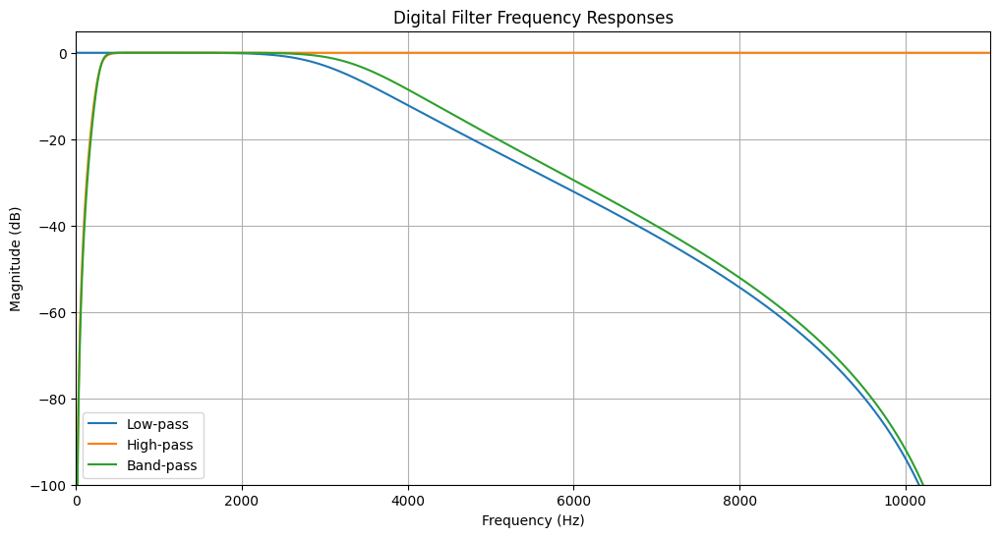

In [19]:
filters = {
    "Low-pass": lowpass_sos,
    "High-pass": highpass_sos,
    "Band-pass": bandpass_sos
}

plt.figure(figsize=(12, 6))

for name, sos in filters.items():

    frequencies, response = sosfreqz(
        sos,
        worN=4096,
        fs=fs
    )

    magnitude_db = 20 * np.log10(
        np.maximum(np.abs(response), 1e-10)
    )

    plt.plot(
        frequencies,
        magnitude_db,
        label=name
    )

plt.title("Digital Filter Frequency Responses")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")

plt.ylim(-100, 5)
plt.xlim(0, fs/2)

plt.legend()
plt.grid()

plt.show()

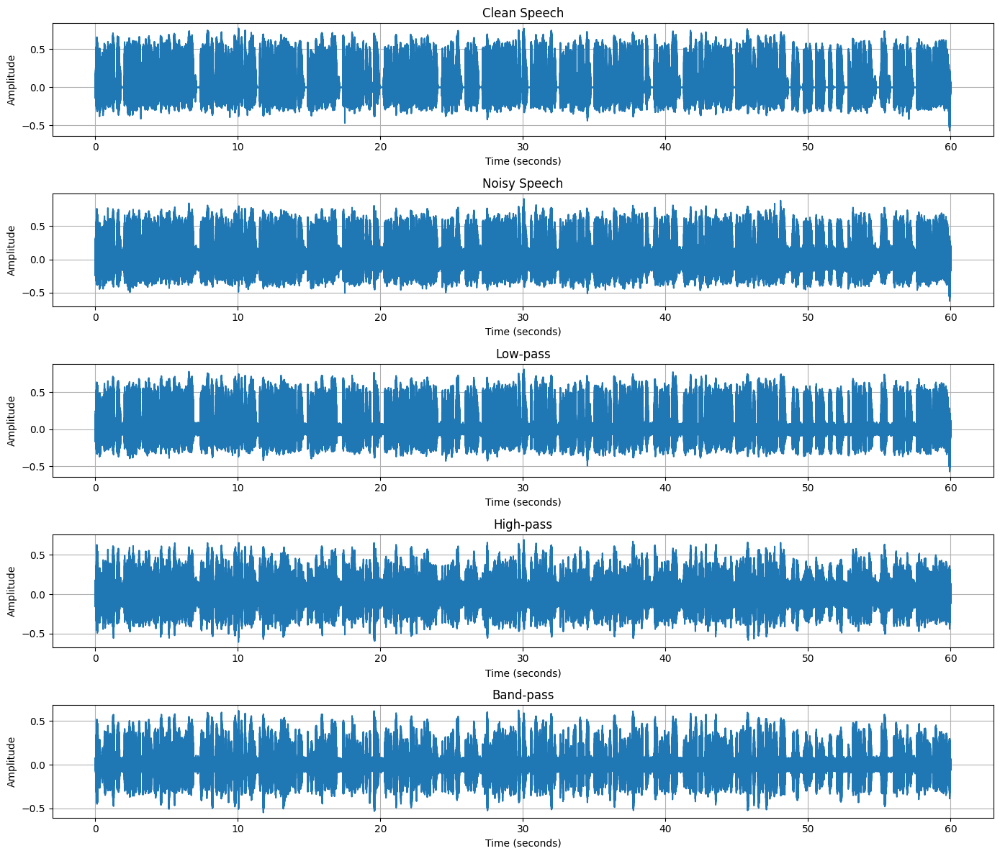

In [20]:
signals = {
    "Clean Speech": clean_speech,
    "Noisy Speech": noisy_speech,
    "Low-pass": lowpass_output,
    "High-pass": highpass_output,
    "Band-pass": bandpass_output
}

time = np.arange(len(clean_speech)) / fs

fig, axes = plt.subplots(
    5,
    1,
    figsize=(14, 12)
)

for ax, (name, signal) in zip(
    axes,
    signals.items()
):

    ax.plot(time, signal)

    ax.set_title(name)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")

    ax.grid()

plt.tight_layout()
plt.show()

In [21]:
def plot_spectrogram(audio, fs, title):

    frequencies, times, Zxx = stft(
        audio,
        fs=fs,
        window="hann",
        nperseg=400,
        noverlap=240,
        nfft=512
    )

    magnitude = np.abs(Zxx)

    magnitude_db = 20 * np.log10(
        magnitude / (magnitude.max() + 1e-10)
        + 1e-10
    )

    plt.figure(figsize=(13, 5))

    plt.pcolormesh(
        times,
        frequencies,
        magnitude_db,
        shading="auto",
        cmap="magma",
        vmin=-80,
        vmax=0
    )

    plt.title(title)
    plt.xlabel("Time (seconds)")
    plt.ylabel("Frequency (Hz)")

    plt.ylim(0, fs/2)

    plt.colorbar(label="Relative Magnitude (dB)")

    plt.show()

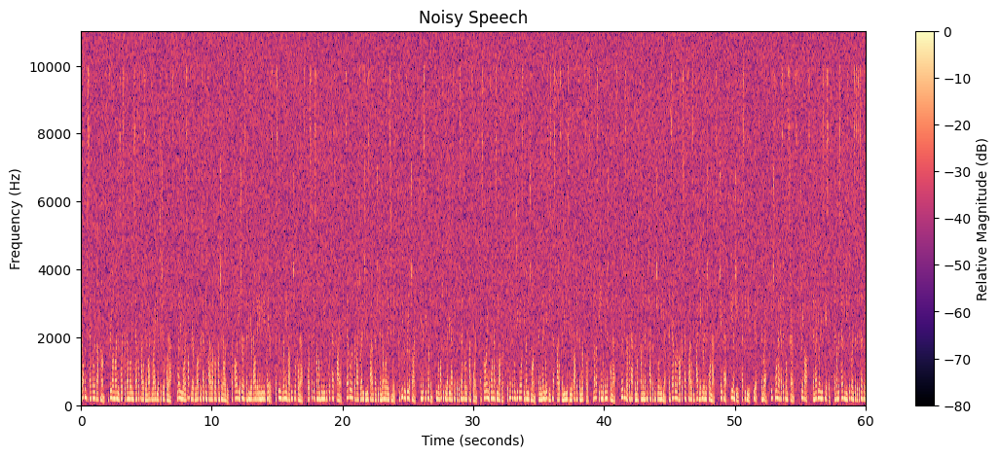

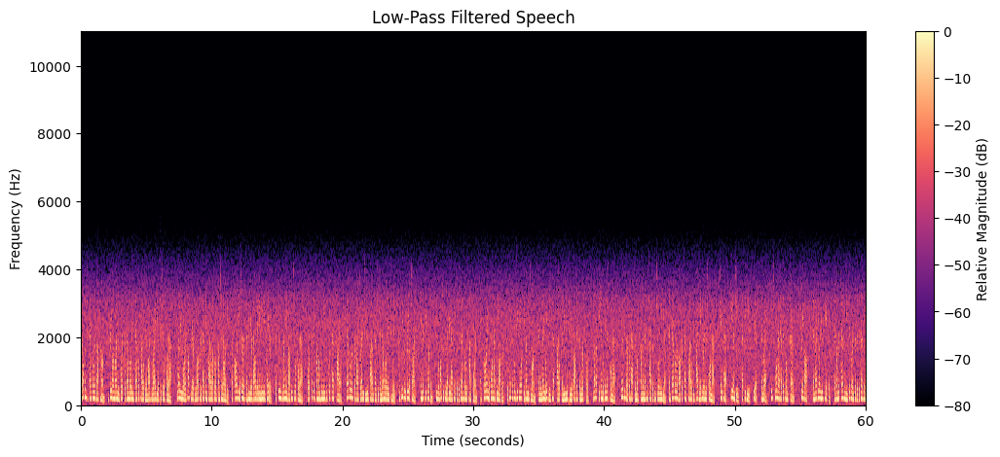

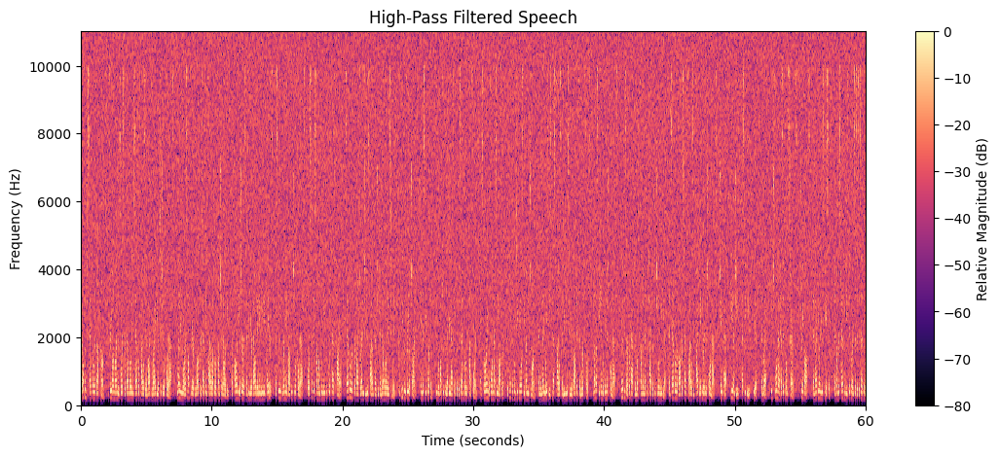

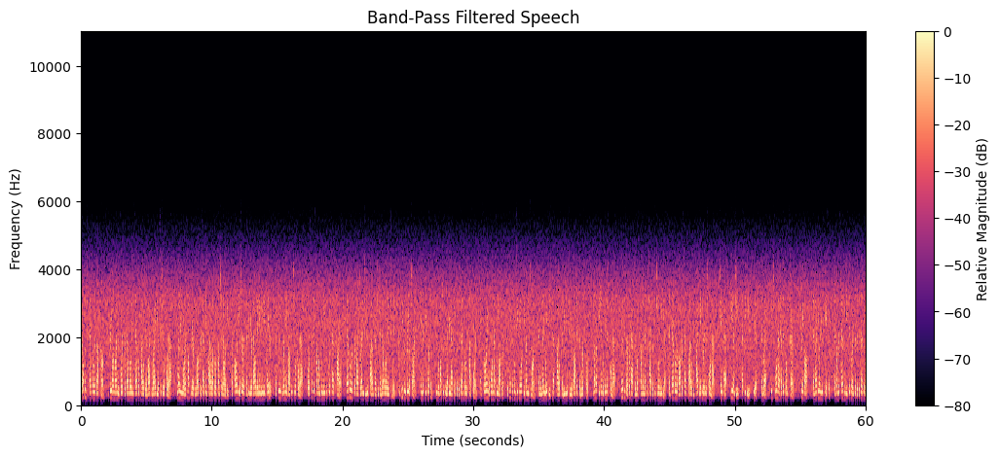

In [22]:
plot_spectrogram(
    noisy_speech,
    fs,
    "Noisy Speech"
)

plot_spectrogram(
    lowpass_output,
    fs,
    "Low-Pass Filtered Speech"
)

plot_spectrogram(
    highpass_output,
    fs,
    "High-Pass Filtered Speech"
)

plot_spectrogram(
    bandpass_output,
    fs,
    "Band-Pass Filtered Speech"
)

In [23]:
def output_snr(clean, enhanced):

    residual_noise = enhanced - clean

    signal_power = np.mean(clean ** 2)

    noise_power = np.mean(residual_noise ** 2)

    return 10 * np.log10(
        signal_power / (noise_power + 1e-12)
    )

In [24]:
input_snr = output_snr(
    clean_speech,
    noisy_speech
)

In [25]:
lowpass_snr = output_snr(
    clean_speech,
    lowpass_output
)

highpass_snr = output_snr(
    clean_speech,
    highpass_output
)

bandpass_snr = output_snr(
    clean_speech,
    bandpass_output
)

In [26]:
print("Input SNR:", input_snr)

print("Low-pass SNR:", lowpass_snr)

print("High-pass SNR:", highpass_snr)

print("Band-pass SNR:", bandpass_snr)

Input SNR: 9.99999999818894
Low-pass SNR: 13.44414678033743
High-pass SNR: 1.6618728890246728
Band-pass SNR: 1.9638164820072257
